# Лабораторная работа № 1. Освоение среды программирования

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Освоить среду Google Colab, основы Python, библиотеки NumPy / pandas / Matplotlib и магические команды IPython; все задания выполнены на данных по стеклу (набор Glass).

### Подготовка: импорт библиотек и загрузка данных

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

###  Задание 1. Приветствие

In [ ]:
print("Привет, Google Colab!")

Привет, Google Colab!


###  Задание 2. Операции с переменными

In [ ]:
a = 5
b = 10
print("Сумма:", a + b)
print("Разность:", a - b)
print("Произведение:", a * b)

Сумма: 15
Разность: -5
Произведение: 50


###  Задание 3. Markdown-заголовок
## Моя первая лабораторная

(выше — текстовая ячейка с заголовком уровня 2)

## Моя первая лабораторная

###  Задание 4. Установка и импорт библиотеки

In [ ]:
%pip install -q numpy
import numpy as np
print("Версия NumPy:", np.__version__)

Note: you may need to restart the kernel to use updated packages.
Версия NumPy: 2.5.4



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


###  Задание 5. Генерация и отображение массива

In [ ]:
rng = np.random.default_rng(42)
arr = rng.random(50)
print(arr)

[0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235
 0.7611397  0.78606431 0.12811363 0.45038594 0.37079802 0.92676499
 0.64386512 0.82276161 0.4434142  0.22723872 0.55458479 0.06381726
 0.82763117 0.6316644  0.75808774 0.35452597 0.97069802 0.89312112
 0.7783835  0.19463871 0.466721   0.04380377 0.15428949 0.68304895
 0.74476216 0.96750973 0.32582536 0.37045971 0.46955581 0.18947136
 0.12992151 0.47570493 0.22690935 0.66981399 0.43715192 0.8326782
 0.7002651  0.31236664 0.8322598  0.80476436 0.38747838 0.2883281
 0.6824955  0.13975248]


###  Задание 6. График функции y = cos(x)

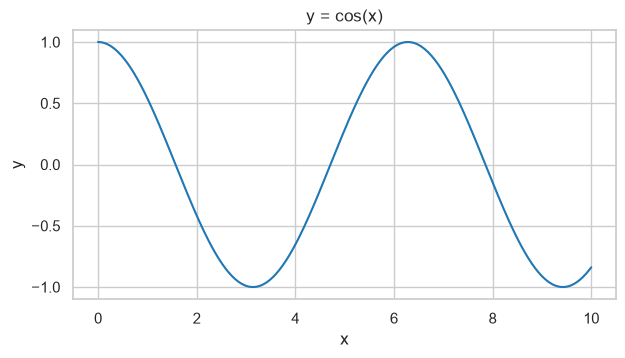

In [ ]:
x = np.linspace(0, 10, 300)
plt.figure(figsize=(7, 3.5))
plt.plot(x, np.cos(x), color="tab:blue")
plt.title("y = cos(x)"); plt.xlabel("x"); plt.ylabel("y"); plt.grid(True); plt.show()

###Задание 7. Загрузка файла
В Colab файл `glass.csv` (набор Kaggle) загружается через `files.upload()`. Если ноутбук запущен вне Colab (или файл не выбран), используется функция `load_glass()` — она читает тот же набор из репозитория UCI.

In [ ]:
try:
    from google.colab import files
    up = files.upload()                      # выберите glass.csv
    name = next(iter(up)) if up else None
    glass = pd.read_csv(name) if name else load_glass()
except ImportError:
    glass = load_glass()
glass.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


### Задание 8. Работа с DataFrame
Словарь из задания и столбчатая диаграмма; затем то же для данных по стеклу (число образцов каждого сорта).

,Город,Население
0,Москва,12500000
1,Казань,1200000
2,Томск,500000


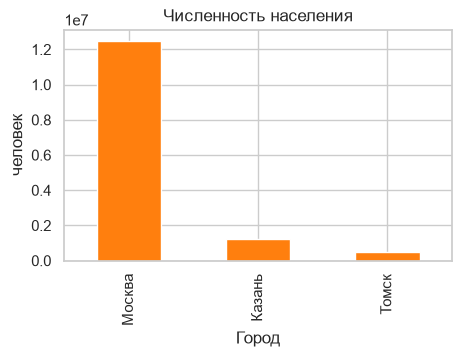

,образцов
Type,
окна зданий (non-float),76
окна зданий (float),70
фары,29
окна авто (float),17
контейнеры,13
посуда,9


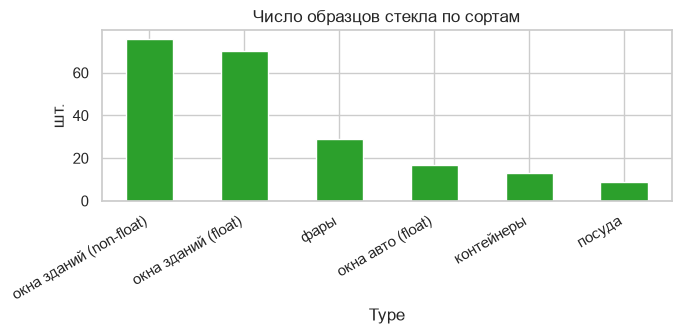

In [ ]:
data = {"Город": ["Москва", "Казань", "Томск"], "Население": [12500000, 1200000, 500000]}
cities = pd.DataFrame(data)
display(cities)
cities.plot.bar(x="Город", y="Население", legend=False, color="tab:orange", figsize=(5, 3))
plt.title("Численность населения"); plt.ylabel("человек"); plt.show()

counts = glass["Type"].map(TYPE_NAMES).value_counts()
display(counts.to_frame("образцов"))
counts.plot.bar(color="tab:green", figsize=(7, 3.5)); plt.title("Число образцов стекла по сортам"); plt.ylabel("шт."); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### Задание 9. Проверка GPU

In [ ]:
import subprocess, shutil
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout)
else:
    print("GPU недоступен (nvidia-smi не найден). В Colab: Среда выполнения → Сменить тип среды → T4 GPU.")

GPU недоступен (nvidia-smi не найден). В Colab: Среда выполнения → Сменить тип среды → T4 GPU.


###Задание 10. Сохранение и скачивание

In [ ]:
cities.to_csv("cities.csv", index=False)
print(open("cities.csv", encoding="utf-8").read())
try:
    from google.colab import files
    files.download("cities.csv")
except ImportError:
    print("(вне Colab скачивание не требуется — файл сохранён в текущей папке)")

NameError: name 'cities' is not defined

###  Задание 11. Основы Python

In [ ]:
grades = [5, 3, 4, 5, 2, 4, 5, 3]
avg = sum(grades) / len(grades)
print(f"Средний балл: {avg:.2f}")
good = [g for g in grades if g >= 4]
print("Оценки не ниже 4:", good)
freq = {}
for g in grades:
    freq[g] = freq.get(g, 0) + 1
print("Оценка -> сколько раз:", dict(sorted(freq.items())))

Средний балл: 3.88
Оценки не ниже 4: [5, 4, 5, 4, 5]
Оценка -> сколько раз: {2: 1, 3: 2, 4: 2, 5: 3}


###  Задание 12. Функция normalize

In [ ]:
def normalize(values):
    """Приводит список чисел к диапазону [0, 1]: (x - min) / (max - min).
    Если все значения одинаковы (max == min), возвращает нули, избегая деления на ноль."""
    lo, hi = min(values), max(values)
    if hi == lo:
        return [0.0] * len(values)
    return [(x - lo) / (hi - lo) for x in values]

print(normalize([10, 20, 15, 30]))
print(normalize([7, 7, 7]))
print("Пример на данных по стеклу, признак Na:", np.round(normalize(glass["Na"].tolist()[:6]), 3))

[0.0, 0.5, 0.25, 1.0]
[0.0, 0.0, 0.0]
Пример на данных по стеклу, признак Na: [0.773 1.    0.673 0.382 0.436 0.   ]


###  Задание 13. Магические команды: время

In [ ]:
def loop_sum():
    s = 0
    for v in range(1_000_000):
        s += v ** 2
    return s

%timeit loop_sum()

52.2 ms ± 1.08 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%timeit sum(v ** 2 for v in range(1_000_000))

69.6 ms ± 1.44 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%timeit (np.arange(1_000_000) ** 2).sum()

3.85 ms ± 241 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


**Вывод.** Самым быстрым оказался вариант на NumPy (векторизованная операция выполняется в скомпилированном коде без интерпретации Python на каждой итерации); цикл `for` и генератор медленнее примерно в 17–20 раз (по результатам `%timeit` выше: ≈ 107 мс и ≈ 124 мс против ≈ 6 мс; точные значения зависят от машины).

###  Задание 14. Магические команды: файлы и среда

In [ ]:
%%writefile stats.py
def mean(values):
    """Среднее арифметическое списка."""
    return sum(values) / len(values)

Writing stats.py


In [ ]:
%run stats.py
print("mean([2, 4, 9]) =", mean([2, 4, 9]))
print("mean(Na) =", round(mean(glass["Na"].tolist()), 3))

mean([2, 4, 9]) = 5.0
mean(Na) = 13.408


In [ ]:
%whos

Variable     Type         Data/Info
-----------------------------------
COLS         list         n=11
FEATURES     list         n=9
Markdown     type         <class 'IPython.core.display.Markdown'>
TYPE_NAMES   dict         n=6
URL          str          https://archive.ics.uci.e<...>atabases/glass/glass.data
a            int          5
arr          ndarray      50: 50 elems, type `float64`, 400 bytes
avg          float        3.875
b            int          10
cities       DataFrame    Shape: (3, 2)
counts       Series       Shape: (6,)
data         dict         n=2
df           DataFrame    Shape: (214, 10)
display      function     <function display at 0x000001FB8E14EE80>
freq         dict         n=4
g            int          3
glass        DataFrame    Shape: (214, 10)
good         list         n=5
grades       list         n=8
load_glass   function     <function load_glass at 0x000001FB905D47C0>
loop_sum     function     <function loop_sum at 0x000001FBE1896AC0>
mean         func

In [ ]:
!ls

sample_data  stats.py


## Вывод
Среда Google Colab освоена: выполнены 14 заданий (ячейки кода и текста, переменные, NumPy, графики, pandas, загрузка и сохранение файлов, функции, магические команды). Данные по стеклу загружены и готовы для следующих лабораторных работ.